# Image Pyramids: Scaling Down and Up

An **image pyramid** is a stack of copies of the same image at decreasing resolutions. Pyramids are used to search for objects at every scale, to speed up matching by starting with a coarse image, and to store an image in a form that can be rebuilt exactly.

Photo credit: <https://www.flickr.com/photos/eurosporttuning/16442169022>

This notebook does the following on a road photo with a car, a motorcycle and a speed sign:
1. Builds a **Gaussian pyramid** with `cv2.pyrDown`.
2. Compares `pyrDown` with plain subsampling and with `cv2.resize`, to show why blurring comes first.
3. Scales back up with `cv2.pyrUp` and measures the loss.
4. Builds a **Laplacian pyramid**, which stores the detail that is lost, and rebuilds the image exactly.
5. Saves all results to `output/`.

## 1. Imports

- `cv2` (OpenCV): image I/O, pyramids and resizing
- `matplotlib`: displaying images
- `numpy`: array operations
- `pathlib`: file paths that work on any OS

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.dpi"] = 80  # keeps the saved notebook small

## 2. How the pyramids are built

- **`pyrDown`** blurs the image with a 5 × 5 Gaussian kernel and then keeps every second row and column. The result is half the width and height. Blurring first removes the detail that would otherwise alias, meaning it would turn into false patterns.
- **`pyrUp`** doubles the size. It inserts zero rows and columns, and then applies the same Gaussian filter, scaled to restore the brightness. The new pixels are estimates, so the result is blurrier than the original.

The **Gaussian pyramid** is $G_0$ (the original), $G_{i+1} = \text{pyrDown}(G_i)$.

The **Laplacian pyramid** stores what is lost at each step: $L_i = G_i - \text{pyrUp}(G_{i+1})$, with the coarsest level kept as $G_n$. Each $L_i$ holds the detail of its level, and the original is rebuilt exactly by $G_i = L_i + \text{pyrUp}(G_{i+1})$, starting from the top.

## 3. Configuration

- `INPUT_PATH`: the road photo. Photo credit: see the top of the notebook.
- `LEVELS`: the number of times the image is scaled down.
- `CROP`: the `(top, bottom, left, right)` region of the motorcycle, used for the close-up comparison in section 5.
- All results are saved to `OUTPUT_DIR`.

In [2]:
INPUT_PATH = Path("Self_Driving.jpg")
OUTPUT_DIR = Path("output")

LEVELS = 3
CROP = (240, 420, 120, 280)  # (top, bottom, left, right) of the motorcycle

## 4. Load the image and helper functions

Helper functions:
- `load_image` wraps `cv2.imread`, which returns `None` on failure instead of raising an error.
- `show_images` shows several images side by side. Colour images are converted from BGR to RGB before display.
- `gaussian_pyramid` returns the list of levels from `pyrDown`.
- `laplacian_pyramid` returns the list of detail levels and the coarsest level.
- `reconstruct` rebuilds the image from a Laplacian pyramid.
- `to_uint8` makes a signed detail image displayable, by taking the absolute value and scaling it.
- `save_image` writes an image and checks the result.

In [3]:
def load_image(path: Path) -> np.ndarray:
    """Load a colour image with OpenCV (BGR order) and raise a clear error if it fails."""
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path.resolve()}")
    return image


def show_images(images: dict[str, np.ndarray], cols: int | None = None, size: float = 5.0) -> None:
    """Show several images side by side. Colour images are converted from BGR to RGB for matplotlib."""
    cols = cols or len(images)
    rows = -(-len(images) // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75),
                             squeeze=False, layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, img) in zip(axes.ravel(), images.items()):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    plt.show()


def gaussian_pyramid(img: np.ndarray, levels: int) -> list[np.ndarray]:
    """Levels G0 (the original) to G_levels, each half the size of the one before."""
    pyramid = [img]
    for _ in range(levels):
        pyramid.append(cv2.pyrDown(pyramid[-1]))
    return pyramid


def laplacian_pyramid(gaussian: list[np.ndarray]) -> list[np.ndarray]:
    """Detail levels L_i = G_i - pyrUp(G_i+1), followed by the coarsest level."""
    levels = []
    for fine, coarse in zip(gaussian[:-1], gaussian[1:]):
        up = cv2.pyrUp(coarse.astype(np.float32), dstsize=(fine.shape[1], fine.shape[0]))
        levels.append(fine.astype(np.float32) - up)
    levels.append(gaussian[-1].astype(np.float32))
    return levels


def reconstruct(laplacian: list[np.ndarray]) -> np.ndarray:
    """Rebuild the original image from a Laplacian pyramid, starting from the coarsest level."""
    img = laplacian[-1]
    for detail in reversed(laplacian[:-1]):
        img = detail + cv2.pyrUp(img, dstsize=(detail.shape[1], detail.shape[0]))
    return img


def to_uint8(values: np.ndarray) -> np.ndarray:
    """Make a signed detail image displayable: absolute value, scaled to 0-255."""
    return cv2.normalize(np.abs(values), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)


def save_image(path: Path, image: np.ndarray) -> None:
    """Save a BGR or single-channel image with OpenCV, raising an error if it fails."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not write image: {path.resolve()}")
    print(f"Saved {path}")

Image size (height, width): (487, 740)


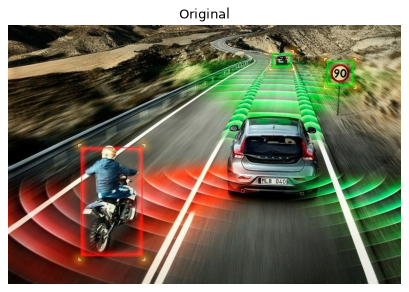

In [4]:
image = load_image(INPUT_PATH)
print(f"Image size (height, width): {image.shape[:2]}")
show_images({"Original": image})

## 5. The Gaussian pyramid

Each level is half the size of the one before. The sizes are rounded up, so an odd size such as 487 becomes 244.

Level 0: 740 x 487
Level 1: 370 x 244
Level 2: 185 x 122
Level 3: 93 x 61


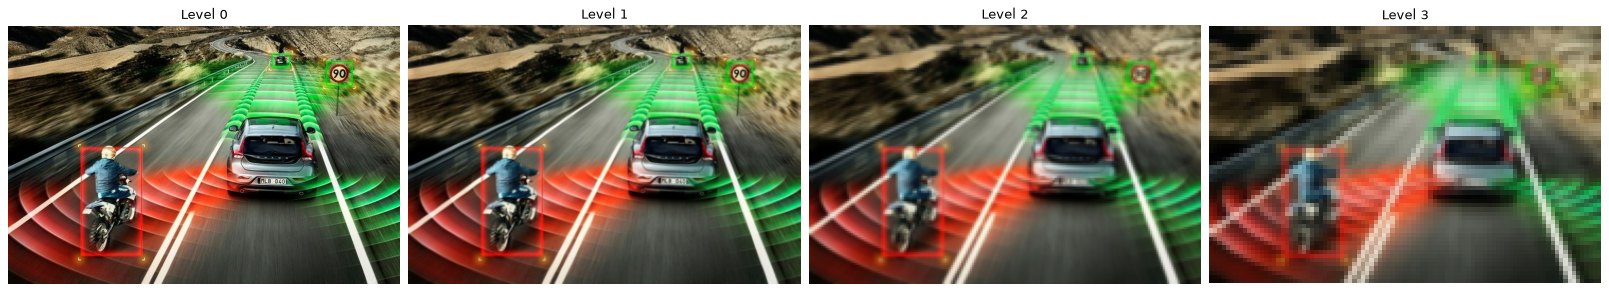

In [5]:
gaussian = gaussian_pyramid(image, LEVELS)
for i, level in enumerate(gaussian):
    print(f"Level {i}: {level.shape[1]} x {level.shape[0]}")

show_images({f"Level {i}": level for i, level in enumerate(gaussian)}, cols=LEVELS + 1)

## 6. Why the blur comes first

Subsampling without a blur keeps every second pixel and drops the rest. Fine texture then aliases: the dashed lane markings and the fence turn into false patterns. `pyrDown` blurs first, and `cv2.resize` with `INTER_AREA` averages the pixels, which is the same idea. The crop below is the motorcycle, shown at the same size for the three methods.

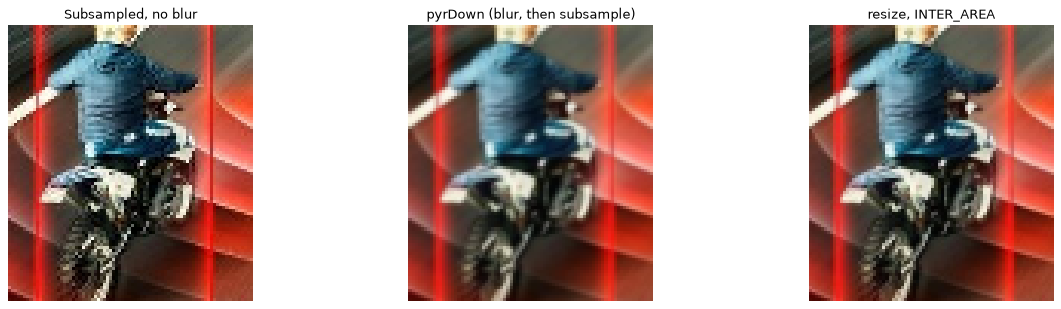

In [6]:
half_plain = image[::2, ::2]  # no blur
half_pyr = cv2.pyrDown(image)
half_area = cv2.resize(image, (half_pyr.shape[1], half_pyr.shape[0]), interpolation=cv2.INTER_AREA)

half = lambda box: tuple(v // 2 for v in box)
t2, b2, l2, r2 = half(CROP)

show_images({
    "Subsampled, no blur": half_plain[t2:b2, l2:r2],
    "pyrDown (blur, then subsample)": half_pyr[t2:b2, l2:r2],
    "resize, INTER_AREA": half_area[t2:b2, l2:r2],
}, cols=3)

## 7. Scaling back up with `pyrUp`

`pyrUp` doubles the size, so the coarsest level is brought back to the size of the original one level at a time. The loss is measured as the mean absolute difference from the original pixels, on a scale of 0 to 255.

Mean absolute error after pyrDown to level 3 and pyrUp: 21.13 (0 to 255 scale)


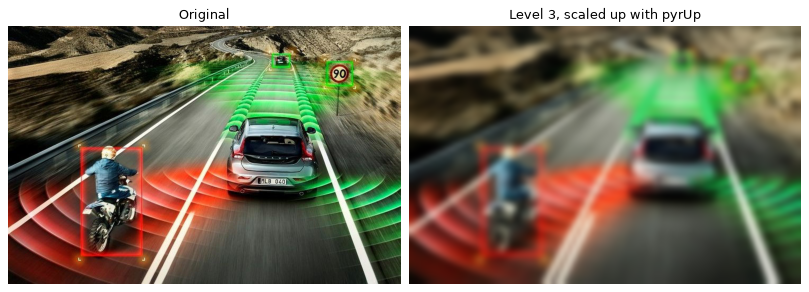

In [7]:
restored = gaussian[LEVELS]
for i in range(LEVELS - 1, -1, -1):
    restored = cv2.pyrUp(restored, dstsize=(gaussian[i].shape[1], gaussian[i].shape[0]))

error = np.abs(restored.astype(np.float32) - image.astype(np.float32)).mean()
print(f"Mean absolute error after pyrDown to level {LEVELS} and pyrUp: {error:.2f} (0 to 255 scale)")

show_images({
    f"Original": image,
    f"Level {LEVELS}, scaled up with pyrUp": restored,
}, cols=2)

## 8. The Laplacian pyramid: the lost detail

The Laplacian levels hold the difference between each level and the blurred version of it. They are mostly close to zero, except at edges and texture. The image is rebuilt from the coarsest level and the detail levels, and the error is printed to show that nothing is lost.

For display, the detail levels are shown as the absolute value, scaled to 0-255.

Largest pixel difference after reconstruction: 0.0000
Pixels that differ after rounding to uint8: 0


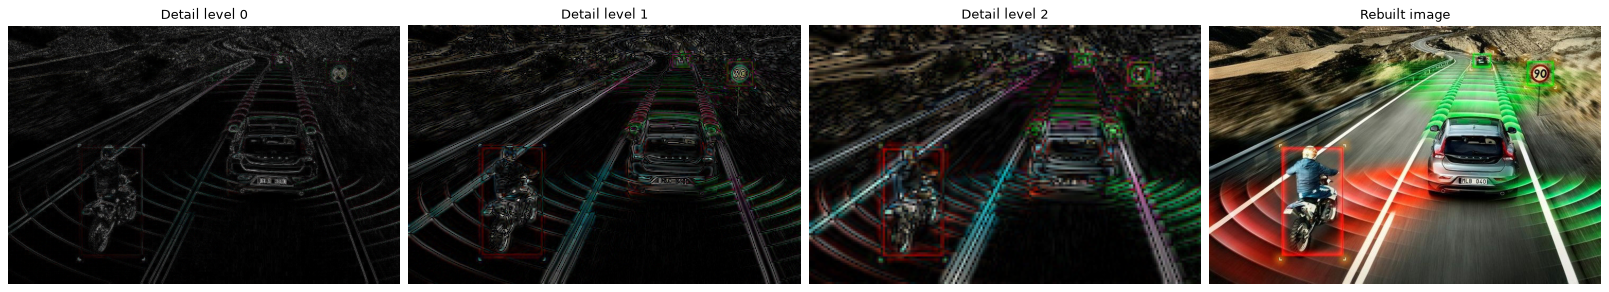

In [8]:
laplacian = laplacian_pyramid(gaussian)
rebuilt = reconstruct(laplacian)

rebuilt_uint8 = np.clip(np.round(rebuilt), 0, 255).astype(np.uint8)
max_error = np.abs(rebuilt - image.astype(np.float32)).max()
print(f"Largest pixel difference after reconstruction: {max_error:.4f}")
print(f"Pixels that differ after rounding to uint8: {int((rebuilt_uint8 != image).sum())}")

show_images({
    **{f"Detail level {i}": to_uint8(level) for i, level in enumerate(laplacian[:-1])},
    "Rebuilt image": rebuilt_uint8,
}, cols=LEVELS + 1)

## 9. Save the results

All results are written to `OUTPUT_DIR`, using the input file name as a prefix.

In [9]:
stem = INPUT_PATH.stem
outputs = {
    **{f"gaussian_level_{i}": level for i, level in enumerate(gaussian)},
    **{f"laplacian_level_{i}": to_uint8(level) for i, level in enumerate(laplacian[:-1])},
    "pyrup_from_level_%d" % LEVELS: restored,
    "rebuilt": rebuilt_uint8,
}
for suffix, result in outputs.items():
    save_image(OUTPUT_DIR / f"{stem}_{suffix}.jpg", result)

Saved output/Self_Driving_gaussian_level_0.jpg
Saved output/Self_Driving_gaussian_level_1.jpg
Saved output/Self_Driving_gaussian_level_2.jpg
Saved output/Self_Driving_gaussian_level_3.jpg
Saved output/Self_Driving_laplacian_level_0.jpg
Saved output/Self_Driving_laplacian_level_1.jpg
Saved output/Self_Driving_laplacian_level_2.jpg
Saved output/Self_Driving_pyrup_from_level_3.jpg
Saved output/Self_Driving_rebuilt.jpg


## 10. Conclusion

- A **Gaussian pyramid** is a stack of blurred, half-size copies. `pyrDown` blurs before it subsamples, which avoids aliasing.
- **`pyrUp` cannot undo `pyrDown`.** The detail removed by the blur is lost, so the round trip is blurry. The error is printed in section 7.
- The **Laplacian pyramid** keeps the lost detail as separate levels. It is exactly invertible, which is why it is used for compression and for blending images.
- Pyramids give **multi-scale** search. Matching at each level finds objects of different sizes, which is the same idea as the multi-scale template matching in an earlier notebook, but computed on a stack of images.

**Current standards beyond this notebook**
- **Feature pyramid networks (FPN, 2017)** build the pyramid inside a convolutional neural network, from its feature maps rather than from the image. Object detectors such as Faster R-CNN and RetinaNet use them to detect objects at several sizes in one pass.
- **Scale-space in SIFT** uses a pyramid of Gaussian-blurred images, with differences between neighbouring levels, to find keypoints at the right scale. It is the classical version of the same idea.